# NN_L4_cifar_curves

**CIFAR-10: a small CNN with and without data augmentation, and plain vs residual 32-layer networks (training loss), seed 20261108.**

Neural Networks and Deep Learning (NN), Lecture 4 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L4/NN_L4_cifar_curves/NN_L4_cifar_curves.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

Augmentation narrows the train-validation gap; the shortcut makes a 32-layer network trainable.

cnn: test accuracy (%) = 86.56   [cifar.cnn.test_acc]
cnn_aug: test accuracy (%) = 86.86   [cifar.cnn_aug.test_acc]
plain32: test accuracy (%) = 79.96   [cifar.plain32.test_acc]
res32: test accuracy (%) = 87.81   [cifar.res32.test_acc]
plain-32 final training loss = 0.557   [cifar.plain32.train_loss]
ResNet-32 final training loss = 0.291   [cifar.res32.train_loss]


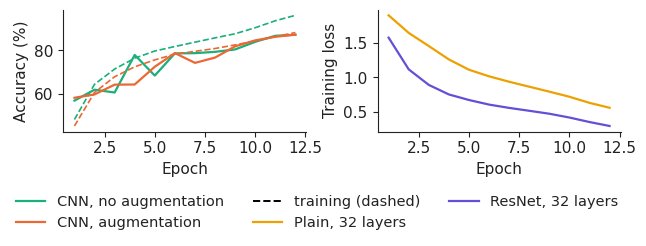

In [3]:
import json, urllib.request
_F = 'cifar_curves_results.json'
R = json.load(open(_F)) if os.path.isfile(_F) else json.load(urllib.request.urlopen(REPO + 'Quantlets/L4/NN_L4_cifar_curves/' + _F))
for k in ['cnn', 'cnn_aug', 'plain32', 'res32']:
    show(f'cifar.{k}.test_acc', f'{k}: test accuracy (%)', round(100 * R[k]['test_acc'], 2))
show('cifar.plain32.train_loss', 'plain-32 final training loss', round(R['plain32']['train_loss'][-1], 3)); show('cifar.res32.train_loss', 'ResNet-32 final training loss', round(R['res32']['train_loss'][-1], 3))
fig, axes = plt.subplots(1, 2, figsize=(6.4, 2.5)); ep = np.arange(1, len(R['cnn']['train_loss']) + 1)
for k, c, l in [('cnn', PAL['benchmark'], 'CNN, no augmentation'), ('cnn_aug', PAL['model'], 'CNN, augmentation')]:
    axes[0].plot(ep, 100 * np.array(R[k]['train_acc']), color=c, ls='--', lw=1.2); axes[0].plot(ep, 100 * np.array(R[k]['valid_acc']), color=c, lw=1.6, label=l)
for k, c, l in [('plain32', PAL['alt'], 'Plain, 32 layers'), ('res32', '#6250d6', 'ResNet, 32 layers')]:
    axes[1].plot(ep, R[k]['train_loss'], color=c, lw=1.6, label=l)
axes[0].set_ylabel('Accuracy (%)'); axes[1].set_ylabel('Training loss')
for ax in axes: ax.set_xlabel('Epoch')
axes[0].plot([], [], color='k', ls='--', label='training (dashed)'); legend_bottom(fig, ncol=3)
fig.tight_layout(rect=(0, 0.2, 1, 1))
fig.savefig('cifar_curves.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()